# **ANALITICA DE DATOS**

## **UNIDAD 3**

## Nombre y No control:

## Fernando Salazar Pérez - 22111448

Generar el código para explicar el dataset (hacer uso de funciones, graficas que considere necesarios)

In [11]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [12]:
# Librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

ruta_archivo = '/content/drive/MyDrive/Analítica de Datos/Unidad 3/Practica 1/vgsales.xlsx'

# Usamos la variable en memoria ya que vgsales.xlsx no está en el directorio local
df_6_columnas = df[["Name", "Platform", "Year", "Genre", "Publisher", "Global_Sales"]].copy()
df_6_columnas["Year"] = df_6_columnas["Year"].astype("Int64")

# Limpiar valores nulos para asegurar un entrenamiento fluido
# Corregido: cambiamos df_6 por df_6_columnas
df_clean = df_6_columnas.dropna().copy()

# Verificar que el dataset no esté vacío antes de continuar
if not df_clean.empty:
    # Codificar variables categóricas (Platform y Publisher) a valores numéricos
    le_platform = LabelEncoder()
    le_publisher = LabelEncoder()

    df_clean['Platform_enc'] = le_platform.fit_transform(df_clean['Platform'].astype(str))
    df_clean['Publisher_enc'] = le_publisher.fit_transform(df_clean['Publisher'].astype(str))

    # Definir características (X) y la variable objetivo (y)
    features = ['Platform_enc', 'Year', 'Publisher_enc', 'Global_Sales']
    X = df_clean[features]
    y = df_clean['Genre']

    # Dividir en entrenamiento (75%) y prueba (25%)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=42, stratify=y
    )

    # Entrenar Árbol de Decisión
    dt_model = DecisionTreeClassifier(max_depth=8, random_state=42)
    dt_model.fit(X_train, y_train)
    y_pred_dt = dt_model.predict(X_test)
    print(f"Precisión del Árbol de Decisión: {accuracy_score(y_test, y_pred_dt) * 100:.2f}%")

    # Entrenar Random Forest
    rf_model = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42)
    rf_model.fit(X_train, y_train)
    y_pred_rf = rf_model.predict(X_test)
    print(f"Precisión del Random Forest: {accuracy_score(y_test, y_pred_rf) * 100:.2f}%")

    # Mostrar importancia de las variables
    importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)
    print("\n=== IMPORTANCIA DE LAS VARIABLES (RANDOM FOREST) ===")
    print(importances)
else:
    print("El dataset está vacío. Asegúrate de cargar los datos correctamente antes de entrenar los modelos.")

Precisión del Árbol de Decisión: 28.28%
Precisión del Random Forest: 30.89%

=== IMPORTANCIA DE LAS VARIABLES (RANDOM FOREST) ===
Publisher_enc    0.357235
Global_Sales     0.300568
Year             0.203948
Platform_enc     0.138248
dtype: float64


=== ESTRUCTURA DEL DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 1 to 16598
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Name          16598 non-null  object 
 1   Platform      16598 non-null  object 
 2   Year          16327 non-null  Int64  
 3   Genre         16598 non-null  object 
 4   Publisher     16540 non-null  object 
 5   Global_Sales  16598 non-null  float64
dtypes: Int64(1), float64(1), object(4)
memory usage: 794.4+ KB
None

=== VALORES NULOS POR COLUMNA ===
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
Global_Sales      0
dtype: int64

=== ESTADÍSTICAS DESCRIPTIVAS (Ventas Globales en millones) ===
count    16598.000000
mean         0.537441
std          1.555028
min          0.010000
25%          0.060000
50%          0.170000
75%          0.470000
max         82.740000
Name: Global_Sales, dtype: float64


/tmp/ipykernel_566/4040320805.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


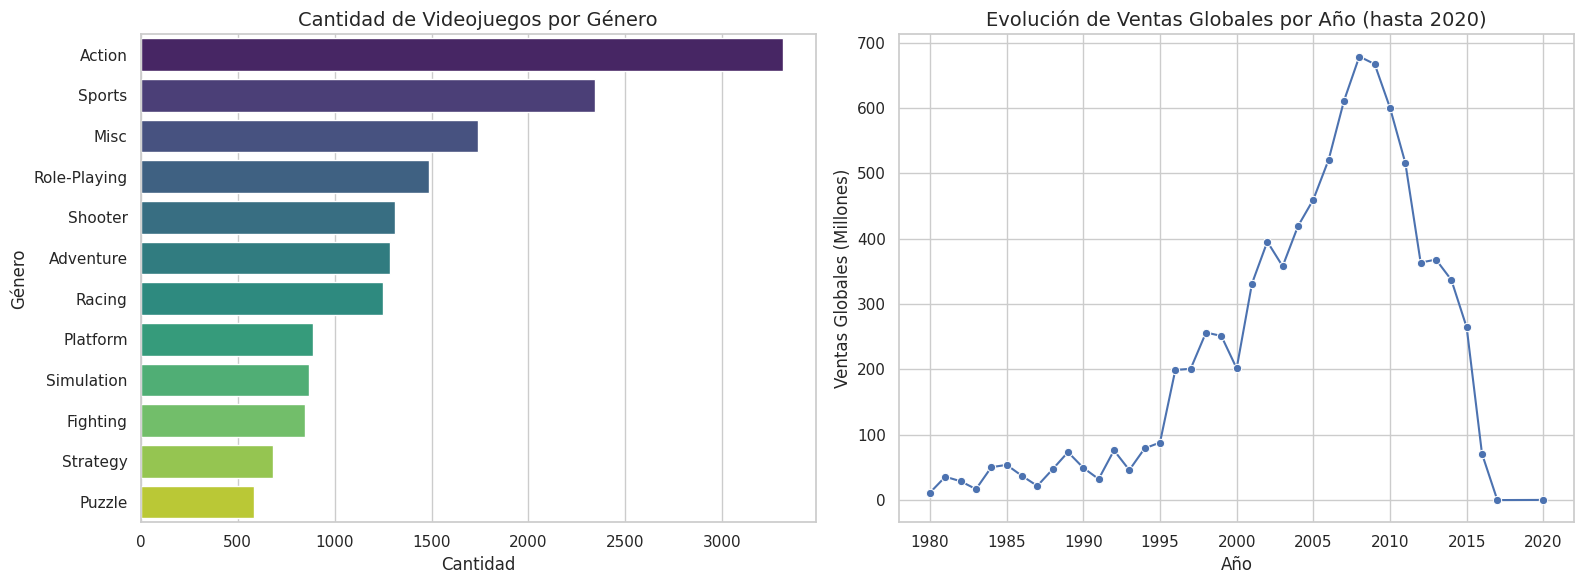

In [14]:
# Información general del Dataset
print("=== ESTRUCTURA DEL DATASET ===")
print(df_6_columnas.info())
print("\n=== VALORES NULOS POR COLUMNA ===")
print(df_6_columnas.isnull().sum())

# Resumen estadístico de las ventas
print("\n=== ESTADÍSTICAS DESCRIPTIVAS (Ventas Globales en millones) ===")
print(df_6_columnas['Global_Sales'].describe())

# Configuración de estilo para las gráficas
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfica 1: Distribución de videojuegos por género
sns.countplot(
    data=df_6_columnas,
    y='Genre',
    order=df_6_columnas['Genre'].value_counts().index,
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Cantidad de Videojuegos por Género', fontsize=14)
axes[0].set_xlabel('Cantidad', fontsize=12)
axes[0].set_ylabel('Género', fontsize=12)

# Gráfica 2: Ventas globales totales acumuladas por año
ventas_por_anio = df_6_columnas[df_6_columnas['Year'] <= 2026].groupby('Year')['Global_Sales'].sum().reset_index()
sns.lineplot(
    data=ventas_por_anio,
    x='Year',
    y='Global_Sales',
    marker='o',
    color='b',
    ax=axes[1]
)
axes[1].set_title('Evolución de Ventas Globales por Año (hasta 2020)', fontsize=14)
axes[1].set_xlabel('Año', fontsize=12)
axes[1].set_ylabel('Ventas Globales (Millones)', fontsize=12)

plt.tight_layout()
plt.show()

In [15]:
# Cargamos el archivo de Excel desde Google Drive para definir 'df'
try:
    df = pd.read_excel(ruta_archivo)

    # Filtramos las 6 columnas especificadas
    df_6_columnas = df[["Name", "Platform", "Year", "Genre", "Publisher", "Global_Sales"]].copy()
    df_6_columnas["Year"] = df_6_columnas["Year"].astype("Int64")

    # Sobrescribimos el dataframe principal con la copia
    df = df_6_columnas.copy()

    # Hacemos que el índice comience en 1
    df.index = range(1, len(df) + 1)

    # Mostramos información básica para confirmar la carga correcta
    print(f"El dataset ahora contiene exactamente {df.shape[1]} columnas.\n")
    print("Columnas seleccionadas:", list(df.columns))
    print("-" * 50)

    # Presentamos las primeras filas de manera limpia
    display(df.head(60))
except Exception as e:
    print(f"Ocurrió un error al procesar el archivo: {e}")

El dataset ahora contiene exactamente 6 columnas.

Columnas seleccionadas: ['Name', 'Platform', 'Year', 'Genre', 'Publisher', 'Global_Sales']
--------------------------------------------------


,Name,Platform,Year,Genre,Publisher,Global_Sales
1,Wii Sports,Wii,2006,Sports,Nintendo,82.74
2,Super Mario Bros.,NES,1985,Platform,Nintendo,40.24
3,Mario Kart Wii,Wii,2008,Racing,Nintendo,35.82
4,Wii Sports Resort,Wii,2009,Sports,Nintendo,33.00
5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,31.37
6,Tetris,GB,1989,Puzzle,Nintendo,30.26
7,New Super Mario Bros.,DS,2006,Platform,Nintendo,30.01
8,Wii Play,Wii,2006,Misc,Nintendo,29.02
9,New Super Mario Bros. Wii,Wii,2009,Platform,Nintendo,28.62
10,Duck Hunt,NES,1984,Shooter,Nintendo,28.31
